# 03 - Exploratory Data Analysis (EDA)

## Objective

The main objectives are to:

- Understand the statistical properties of the data.
- Analyze individual attribute distributions.
- Investigate relationships between attributes.
- Identify correlations and potential redundancy.
- Explore differences between Information Operations
  (IO) and control accounts.
- Identify useful features for account-level profiling
  and subsequent clustering.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

In [5]:
DATA_PATH = Path("data_processed/df_clean_final.csv.gz")

print("Dataset exists:", DATA_PATH.exists())

Dataset exists: True


In [6]:
df_preview = pd.read_csv(DATA_PATH, nrows=5, dtype="string")

display(df_preview)

print("Number of attributes:", len(df_preview.columns))
print("\nAttributes:")

for column in df_preview.columns:
    print(column)

,ioCountry,postid,post_text,application_name,post_language,in_reply_to_postid,in_reply_to_accountid,post_time,accountid,account_profile_description,follower_count,following_count,account_creation_date,is_repost,reposted_accountid,reposted_postid,hashtags,urls,account_mentions,is_control
0,ecuador,0bafe020a260495bee38b98fde83668d924454019b,Vamos a cambiar la forma de hacer comunicación...,2727201c363b6fc4afe259ba4094ae0c49cb4df224,<NA>,<NA>,<NA>,2010-03-13 02:52:00+00:00,22de67d991b31493165b9270f7d8b5b4ce712d5fc8,"#Periodismo, #RelacionesPúblicas, #Comunicac...",1528.0,2619.0,2010-03-11,False,<NA>,<NA>,[],[],[],False
1,ecuador,608fba51f2460c7f1ca527dfc48de2bc858d4ad201,"Damos servicio de manejo de prensa, elaboració...",2727201c363b6fc4afe259ba4094ae0c49cb4df224,<NA>,<NA>,<NA>,2010-03-13 03:08:00+00:00,22de67d991b31493165b9270f7d8b5b4ce712d5fc8,"#Periodismo, #RelacionesPúblicas, #Comunicac...",1528.0,2619.0,2010-03-11,False,<NA>,<NA>,[],[],[],False
2,ecuador,514b2c38b26e240cac85382be74ed7d61a02468ac1,@db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302 Bu...,2727201c363b6fc4afe259ba4094ae0c49cb4df224,<NA>,f29b32f8dbaa1e0f00152decbcc2bd93dddc740464,db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302,2010-03-13 15:26:00+00:00,2c6c0ef5f445760177b016e33b36809bde3c7ac241,<NA>,35.0,215.0,2010-01-28,False,<NA>,<NA>,[],[],['db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302'],False
3,ecuador,e82a816068e88387d19430348f0420b040e0d11b4e,"Mario, debemos denuciar que en los poderes pub...",2727201c363b6fc4afe259ba4094ae0c49cb4df224,<NA>,<NA>,<NA>,2010-03-13 15:32:00+00:00,2c6c0ef5f445760177b016e33b36809bde3c7ac241,<NA>,35.0,215.0,2010-01-28,False,<NA>,<NA>,[],[],[],False
4,ecuador,13ed6aaeec4fffaf840f1c42ff88f5ab2cb324be64,Tambien debemos estar claro que la oposición e...,2727201c363b6fc4afe259ba4094ae0c49cb4df224,<NA>,<NA>,<NA>,2010-03-13 15:35:00+00:00,2c6c0ef5f445760177b016e33b36809bde3c7ac241,<NA>,35.0,215.0,2010-01-28,False,<NA>,<NA>,[],[],[],False


Number of attributes: 20

Attributes:
ioCountry
postid
post_text
application_name
post_language
in_reply_to_postid
in_reply_to_accountid
post_time
accountid
account_profile_description
follower_count
following_count
account_creation_date
is_repost
reposted_accountid
reposted_postid
hashtags
urls
account_mentions
is_control


## B. Descriptive Statistics

This section investigates the statistical characteristics
of the cleaned dataset, including central tendency,
dispersion, and variability.

The objective is to better understand the data and
identify potentially informative features for
account-level profiling and clustering.

we will start with the follower and following counts, it will be done at the accounts level, first lets check how many accounts do we have

In [8]:
CHUNK_SIZE = 200_000

columns = [
    "ioCountry",
    "accountid",
    "post_time",
    "follower_count",
    "following_count"
]

account_keys = ["ioCountry", "accountid"]

df_accounts = pd.DataFrame()

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=columns,
    dtype={"accountid": "string", "ioCountry": "string"},
    chunksize=CHUNK_SIZE
):
    chunk["post_time"] = pd.to_datetime(
        chunk["post_time"],
        errors="coerce",
        utc=True
    )

    chunk = chunk.dropna(
        subset=account_keys + ["post_time"]
    )

    # Keep the most recent record of each account
    chunk = (
        chunk.sort_values("post_time", kind="stable")
        .drop_duplicates(subset=account_keys, keep="last")
    )

    # Combine with previously processed accounts
    df_accounts = pd.concat(
        [df_accounts, chunk],
        ignore_index=True
    )

    df_accounts = (
        df_accounts.sort_values("post_time", kind="stable")
        .drop_duplicates(subset=account_keys, keep="last")
    )

df_accounts = df_accounts.reset_index(drop=True)

print(f"Number of accounts: {len(df_accounts):,}")

display(df_accounts.head())

Number of accounts: 86,525


,ioCountry,post_time,accountid,follower_count,following_count
0,russia_1,2009-11-22 23:59:26+00:00,c5bf20b8b883fd0c5689c64bee8ae7bd81d97698f6,125.0,0.0
1,russia_1,2009-11-23 23:59:58+00:00,be64bf6b9b53f31e552be1bcaa0299143a51797dce,3248.0,2473.0
2,russia_1,2009-11-23 23:59:58+00:00,703a8bb61d6ddb7168f50bebc3a753d88ba09a2d98,33.0,22.0
3,russia_1,2009-11-24 23:59:58+00:00,2e1e7459112a2f14ce968cbc6e967725426962cb85,469.0,537.0
4,russia_1,2009-11-24 23:59:58+00:00,ae36bdb6544c22720f180f2b079218b50b7d3a098e,68.0,167.0


In [9]:
numerical_attributes = [
    "follower_count",
    "following_count"
]

display(
    df_accounts[numerical_attributes]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
follower_count,86521.0,10163.087690,185853.570717,0.0,97.0,385.0,1433.0,13815.0,101518.80,19912528.0
following_count,86522.0,1811.917524,12883.529464,0.0,118.0,406.0,1235.0,5001.0,21654.17,2301841.0


Visualisation:
- Each histogram contains 50 bins, where each bin represents
  an interval of follower or following counts
- The height of each bin represents the number of accounts
within that interval.

We used only the 95th percentile because including extremely large values would stretch the X-axis and make the distribution of most accounts difficult to observe.


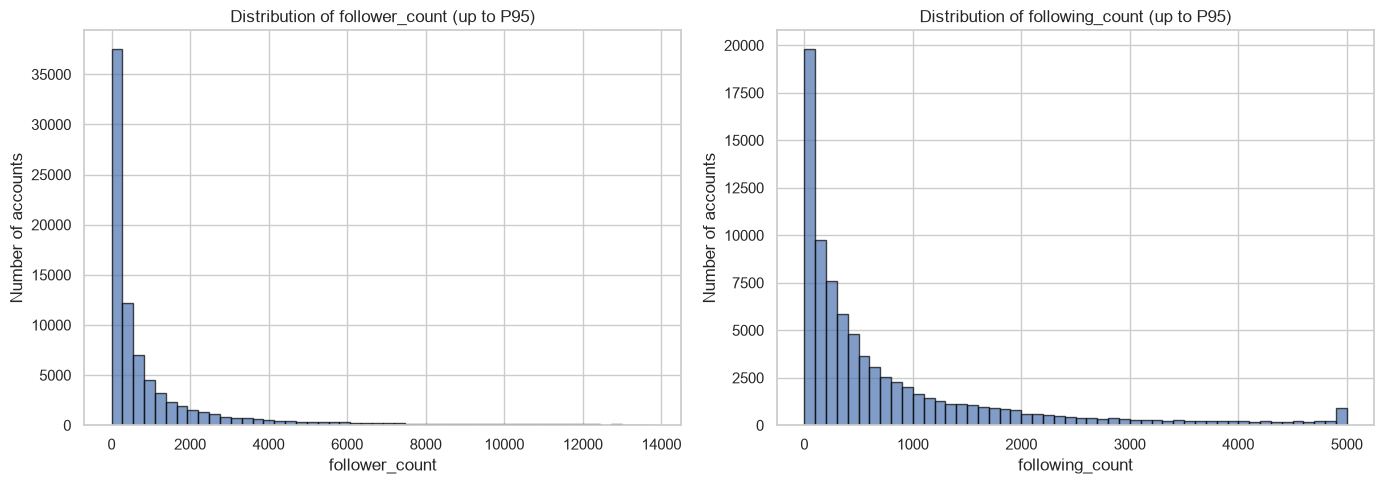

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column in zip(axes, ["follower_count", "following_count"]):

    values = df_accounts[column].dropna()
    upper_limit = values.quantile(0.95)

    ax.hist(
        values[values <= upper_limit],
        bins=50,
        edgecolor="black",
        alpha=0.7
    )

    ax.set_title(f"Distribution of {column} (up to P95)")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of accounts")

plt.tight_layout()
plt.show()

Now we will move to Account Age and Activity Lifespan.

These attributes could be particularly useful for understanding behavioral differences between IO and control accounts.
Because IO accounts may be created and operated for specific information campaigns, while control accounts may be used for ordinary, long-term social media activity.

In [17]:
columns = [
    "ioCountry",
    "accountid",
    "account_creation_date",
    "post_time"
]

df_temporal = pd.DataFrame()

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=columns,
    dtype={"accountid": "string", "ioCountry": "string"},
    chunksize=CHUNK_SIZE
):
    chunk["post_time"] = pd.to_datetime(
        chunk["post_time"], errors="coerce", utc=True
    )

    chunk["account_creation_date"] = pd.to_datetime(
        chunk["account_creation_date"], errors="coerce", utc=True
    )

    chunk = chunk.groupby(account_keys).agg(
        creation_date=("account_creation_date", "min"),
        first_post=("post_time", "min"),
        last_post=("post_time", "max")
    ).reset_index()

    df_temporal = pd.concat(
        [df_temporal, chunk], ignore_index=True
    )

    df_temporal = df_temporal.groupby(account_keys).agg(
        creation_date=("creation_date", "min"),
        first_post=("first_post", "min"),
        last_post=("last_post", "max")
    ).reset_index()

In [19]:
df_temporal["account_age_days"] = (
    df_temporal["last_post"].dt.normalize()
    - df_temporal["creation_date"].dt.normalize()
).dt.days

df_temporal["activity_lifespan_days"] = (
    df_temporal["last_post"].dt.normalize()
    - df_temporal["first_post"].dt.normalize()
).dt.days

display(
    df_temporal[[
        "account_age_days",
        "activity_lifespan_days"
    ]].describe(
        percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
    ).T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
account_age_days,86525.0,993.341000,887.809747,0.0,243.0,750.0,1509.0,2815.0,3353.0,4493.0
activity_lifespan_days,86525.0,40.498943,163.007385,0.0,0.0,0.0,0.0,255.0,889.0,3288.0


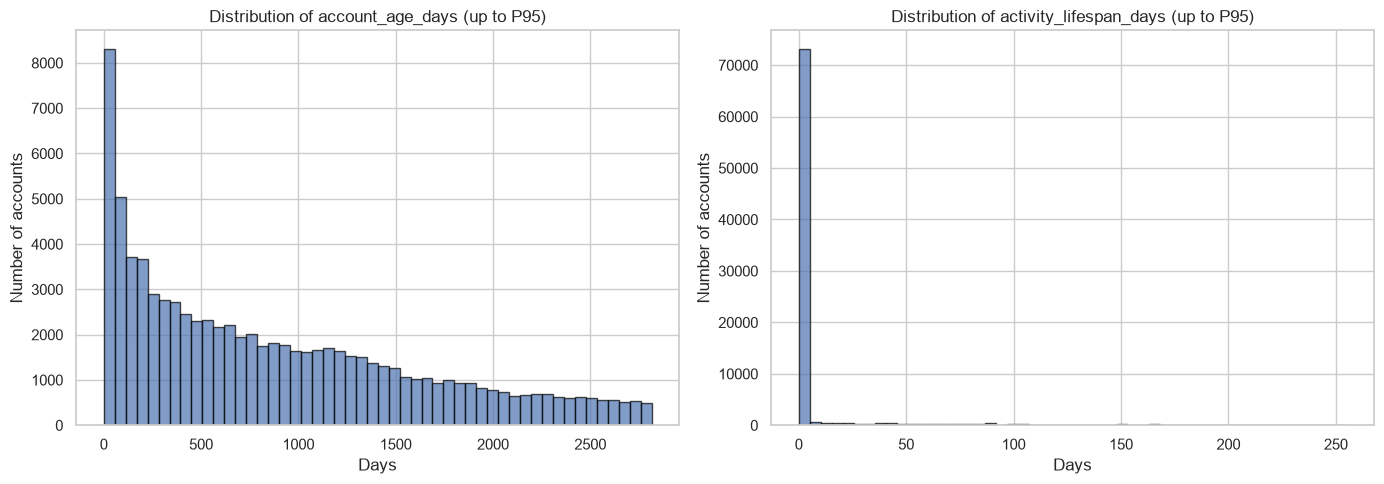

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column in zip(
    axes, ["account_age_days", "activity_lifespan_days"]
):
    values = df_temporal[column].dropna()
    upper_limit = values.quantile(0.95)

    ax.hist(
        values[values <= upper_limit],
        bins=50,
        edgecolor="black",
        alpha=0.7
    )

    ax.set_title(f"Distribution of {column} (up to P95)")
    ax.set_xlabel("Days")
    ax.set_ylabel("Number of accounts")

plt.tight_layout()
plt.show()

### B.3 Number of Posts per Account

We calculate the total number of observed posts for each
account

In [24]:
from collections import Counter

post_counts = Counter()

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=account_keys,
    dtype="string",
    chunksize=CHUNK_SIZE
):
    counts = chunk.groupby(account_keys).size()
    post_counts.update(counts.to_dict())

df_activity = pd.DataFrame(
    [(country, account, count)
     for (country, account), count in post_counts.items()],
    columns=["ioCountry", "accountid", "post_count"]
)

In [25]:
display(
    df_activity[["post_count"]]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
post_count,86525.0,100.696804,1123.533127,1.0,6.0,23.0,84.0,240.0,1386.0,265448.0


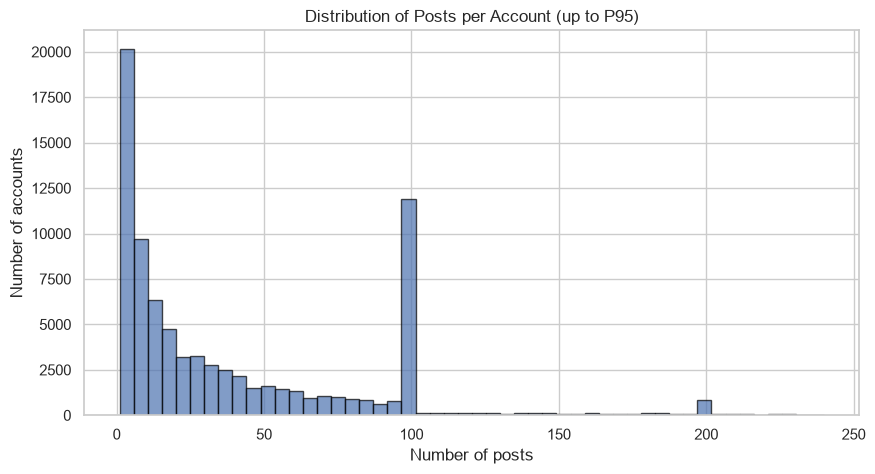

In [26]:
values = df_activity["post_count"]
upper_limit = values.quantile(0.95)

plt.figure(figsize=(10, 5))

plt.hist(
    values[values <= upper_limit],
    bins=50,
    edgecolor="black",
    alpha=0.7
)

plt.title("Distribution of Posts per Account (up to P95)")
plt.xlabel("Number of posts")
plt.ylabel("Number of accounts")
plt.show()

There are 2 spikes at 100 and at 200 posts. This unusual concentration requires further
investigation.

In [27]:
display(
    df_activity["post_count"]
    .value_counts()
    .head(15)
    .rename("Number of accounts")
    .to_frame()
)

,Number of accounts
post_count,
99,11543
1,6027
2,4560
3,3738
4,3089
5,2761
6,2395
7,2123
8,1989


In [28]:
summary_99 = df_activity.groupby("ioCountry").agg(
    total_accounts=("post_count", "size"),
    accounts_with_99_posts=("post_count", lambda x: (x == 99).sum())
)

summary_99["percentage"] = (
    summary_99["accounts_with_99_posts"]
    / summary_99["total_accounts"] * 100
)

display(
    summary_99.sort_values("percentage", ascending=False).round(2)
)

,total_accounts,accounts_with_99_posts,percentage
ioCountry,,,
iran_1,5675,910,16.04
russia_1,34592,5200,15.03
ecuador,21924,2757,12.58
iran_4,10131,1254,12.38
uae,14203,1422,10.01


Accounts with exactly 99 posts appear across all five
information operations, with percentages ranging from
10.01% to 16.04%, so its not a result from a single country.

In [29]:
label_chunks = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=account_keys + ["is_control"],
    dtype="string",
    chunksize=CHUNK_SIZE
):
    label_chunks.append(chunk.drop_duplicates())

df_labels = pd.concat(label_chunks, ignore_index=True)
df_labels = df_labels.dropna().drop_duplicates()

# Exclude accounts with conflicting labels
df_labels = df_labels.drop_duplicates(
    subset=account_keys, keep=False
)

In [30]:
df_activity_labeled = df_activity.merge(
    df_labels,
    on=account_keys,
    how="left"
)

summary_99_class = df_activity_labeled.groupby("is_control").agg(
    total_accounts=("post_count", "size"),
    accounts_with_99_posts=("post_count", lambda x: (x == 99).sum())
)

summary_99_class["percentage"] = (
    summary_99_class["accounts_with_99_posts"]
    / summary_99_class["total_accounts"] * 100
)

display(summary_99_class.round(2))

,total_accounts,accounts_with_99_posts,percentage
is_control,,,
False,10916,20,0.18
True,75608,11523,15.24


Exactly 99 posts are observed in 15.24% of control accounts,
compared to only 0.18% of IO accounts, suggesting a potential
data collection artifact affecting control accounts.
lets check if there is a limit at 99

In [32]:
summary_posts = df_activity_labeled.groupby("is_control").agg(
    total_accounts=("post_count", "size"),
    below_99=("post_count", lambda x: (x < 99).sum()),
    exactly_99=("post_count", lambda x: (x == 99).sum()),
    above_99=("post_count", lambda x: (x > 99).sum()),
    max_posts=("post_count", "max")
)

display(summary_posts)

,total_accounts,below_99,exactly_99,above_99,max_posts
is_control,,,,,
False,10916,5738,20,5158,265448
True,75608,61484,11523,2601,19690


#### Conclusion

The unusual concentration at 99 posts may be related to
the data collection procedure rather than actual account
behavior. Its cause remains unconfirmed. But it can affect clustering,
we will its effect on clustering during feature selection

Now we will calculate the post intensity
### B.4 Posting Intensity

We combine post count and activity lifespan to measure
the average number of posts per day over each account's
observed activity period.

In [35]:
df_activity = df_activity.merge(
    df_temporal[account_keys + ["activity_lifespan_days"]],
    on=account_keys,
    how="left"
)

df_activity["posting_intensity"] = (
    df_activity["post_count"]
    / (df_activity["activity_lifespan_days"] + 1)
)

In [36]:
display(
    df_activity[["posting_intensity"]]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
posting_intensity,86525.0,29.055718,34.651273,0.000893,3.0,11.583333,45.0,99.0,99.0,283.0


In [37]:
print("Accounts with posting intensity of 99:",
      (df_activity["posting_intensity"] == 99).sum())

print("Accounts with 99 posts and zero lifespan:",
      ((df_activity["post_count"] == 99) &
       (df_activity["activity_lifespan_days"] == 0)).sum())

Accounts with posting intensity of 99: 11557
Accounts with 99 posts and zero lifespan: 11516


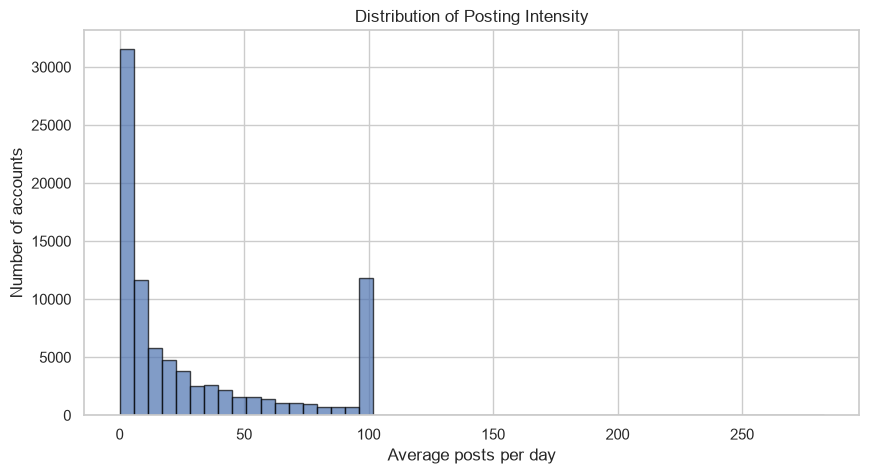

In [38]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_activity["posting_intensity"].dropna(),
    bins=50,
    edgecolor="black",
    alpha=0.7
)

plt.title("Distribution of Posting Intensity")
plt.xlabel("Average posts per day")
plt.ylabel("Number of accounts")

plt.show()

#### Observations

The posting intensity distribution is right-skewed,
with a noticeable concentration at 99 posts per day.

Therefore, posting intensity may also be affected by
the previously identified potential sampling bias.

### B.5 Interaction Behavior

We analyze reposts, replies and mentions to characterize
how accounts interact with other users and disseminate
information.

we will use rations to make the comparison fair between accounts (we want to study the behavior)


In [46]:
columns = account_keys + [
    "is_repost",
    "in_reply_to_postid",
    "in_reply_to_accountid",
    "account_mentions"
]

interaction_chunks = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=columns,
    dtype="string",
    chunksize=CHUNK_SIZE
):
    # Identify reposts
    repost_status = chunk["is_repost"].str.strip().str.lower()

    chunk["repost"] = repost_status.eq("true").fillna(False)
    chunk["known_repost"] = repost_status.isin(["true", "false"])

    # Identify replies
    chunk["reply"] = (
        chunk["in_reply_to_postid"].notna() |
        chunk["in_reply_to_accountid"].notna()
    )

    # Identify posts containing mentions
    mentions = chunk["account_mentions"].str.strip()

    chunk["known_mentions"] = (
        mentions.str.startswith("[", na=False) &
        mentions.str.endswith("]", na=False)
    )

    chunk["has_mention"] = (
        chunk["known_mentions"] &
        ~mentions.str.fullmatch(r"\[\s*\]", na=False)
    )

    # Aggregate information per account
    stats = chunk.groupby(account_keys).agg(
        post_count=("accountid", "size"),
        repost_count=("repost", "sum"),
        known_repost_count=("known_repost", "sum"),
        reply_count=("reply", "sum"),
        mention_count=("has_mention", "sum"),
        known_mention_count=("known_mentions", "sum")
    )

    interaction_chunks.append(stats)

df_interactions = (
    pd.concat(interaction_chunks)
    .groupby(level=[0, 1])
    .sum()
    .reset_index()
)

In [47]:
df_interactions["repost_ratio"] = (
    df_interactions["repost_count"]
    / df_interactions["known_repost_count"].replace(0, np.nan)
)

df_interactions["reply_ratio"] = (
    df_interactions["reply_count"]
    / df_interactions["post_count"]
)

df_interactions["mention_ratio"] = (
    df_interactions["mention_count"]
    / df_interactions["known_mention_count"].replace(0, np.nan)
)

In [48]:
interaction_features = [
    "repost_ratio",
    "reply_ratio",
    "mention_ratio"
]

display(
    df_interactions[interaction_features]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
repost_ratio,86525.0,0.440623,0.398536,0.0,0.0,0.363636,0.877551,1.0,1.0,1.0
reply_ratio,86525.0,0.109589,0.191012,0.0,0.0,0.0,0.142857,0.538462,0.833333,1.0
mention_ratio,86525.0,0.613193,0.385763,0.0,0.25,0.737374,1.0,1.0,1.0,1.0


Each bin represents a ratio interval of 0.05 (5%).

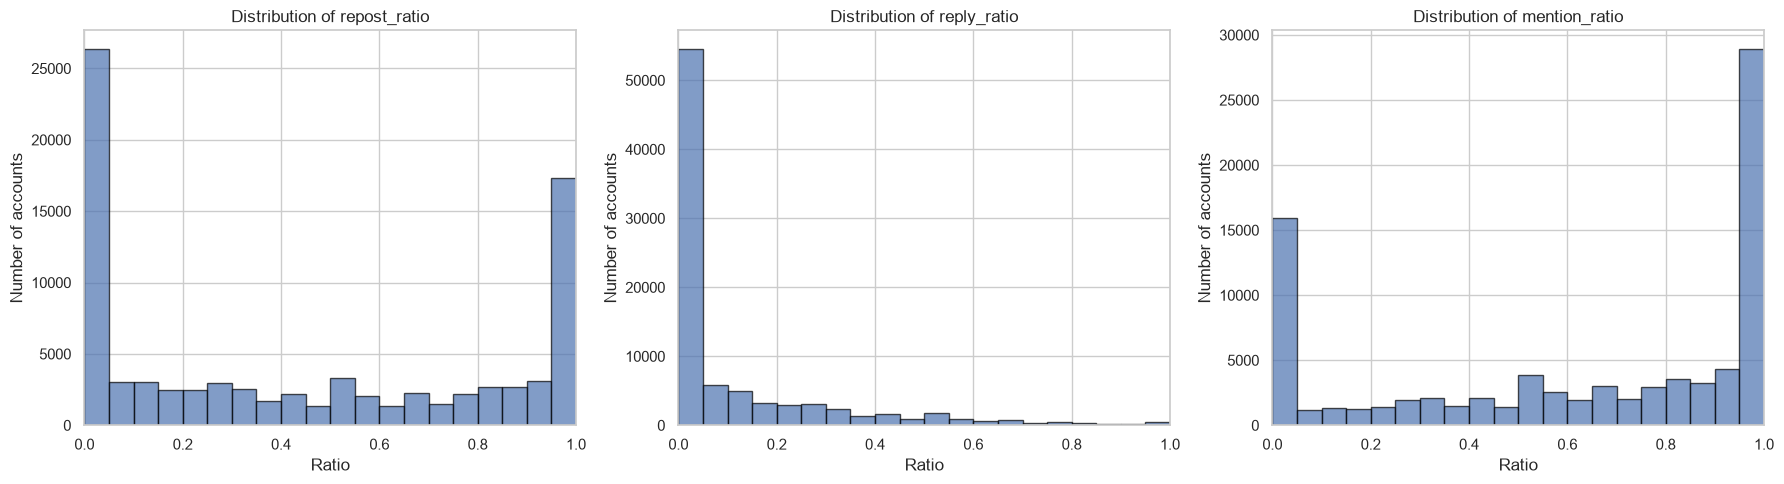

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, column in zip(axes, interaction_features):

    ax.hist(
        df_interactions[column].dropna(),
        bins=np.linspace(0, 1, 21),
        edgecolor="black",
        alpha=0.7
    )

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel("Ratio")
    ax.set_ylabel("Number of accounts")
    ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()

reposts often contain mentions of the original author.
So potential redundancy between repost and mention ratios
will be investigated during correlation analysis.